In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt


In [4]:
import seaborn as sns

In [5]:
from sklearn.model_selection import train_test_split

In [6]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [7]:
import tensorflow as tf

In [8]:
from tensorflow import keras
from tensorflow.keras import layers

In [9]:
print(tf.__version__)

2.22.0-rc0


In [10]:
import pandas as pd

df = pd.read_csv("../data/WineQT.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [11]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [12]:
df.shape

(1143, 13)

In [13]:
df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'Id'],
      dtype='str')

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [15]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.describe()



,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043,804.969379
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824,463.997116
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000,0.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000,411.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000,794.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000,1209.500000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000,1597.000000


In [18]:
print(df.columns.tolist())

['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']


In [19]:
print(df['quality'].value_counts())

quality
5    483
6    462
7    143
4     33
8     16
3      6
Name: count, dtype: int64


In [20]:
X = df.drop('quality', axis=1)
y = df['quality']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1143, 12)
Target Shape: (1143,)


In [21]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the shape of each dataset
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (914, 12)
Testing Features: (229, 12)
Training Target: (914,)
Testing Target: (229,)


In [22]:
from sklearn.preprocessing import StandardScaler

# Create StandardScaler
sc = StandardScaler()

# Scale training data
X_train = sc.fit_transform(X_train)

# Scale testing data
X_test = sc.transform(X_test)

print("Data scaling completed")

Data scaling completed


In [23]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


In [24]:
model = keras.Sequential()

# Input layer and first hidden layer
model.add(layers.Dense(64, activation='relu', input_shape=(12,)))

# Second hidden layer
model.add(layers.Dense(32, activation='relu'))

# Output layer
model.add(layers.Dense(1))

print("ANN Model Created Successfully")

ANN Model Created Successfully


C:\Users\salun\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [25]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │             832 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,945 (11.50 KB)

 Trainable params: 2,945 (11.50 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

print("Model is ready for training")

Model is ready for training


In [27]:
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.2)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 20.2002 - mae: 4.3366 - val_loss: 13.5991 - val_mae: 3.4652
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 8.5361 - mae: 2.6078 - val_loss: 5.0204 - val_mae: 1.8544
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.3241 - mae: 1.4688 - val_loss: 3.2268 - val_mae: 1.4358
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.3580 - mae: 1.2106 - val_loss: 2.7975 - val_mae: 1.3495
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 2.0070 - mae: 1.1267 - val_loss: 2.5792 - val_mae: 1.2743
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.7913 - mae: 1.0641 - val_loss: 2.4247 - val_mae: 1.2292
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.6399 - mae: 1.0170 - val_loss: 2.2916 - val_mae: 1.1958
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.5207 - mae: 0.9795 - val_loss: 2.1724 - val_mae: 1.1644
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.4203 - ma

In [28]:
result = model.evaluate(X_test, y_test)

print("Model Loss:", result[0])
print("Model MAE:", result[1])

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4919 - mae: 0.5293 
Model Loss: 0.4919431805610657
Model MAE: 0.5292789340019226


In [29]:
predictions = model.predict(X_test)

print(predictions[:5])

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
[[5.401756 ]
 [4.6675057]
 [5.5969653]
 [4.8122272]
 [6.078399 ]]


In [30]:
print("Actual Values:")
print(y_test[:5].values)

print("Predicted Values:")
print(predictions[:5])

Actual Values:
[5 6 5 6 6]
Predicted Values:
[[5.401756 ]
 [4.6675057]
 [5.5969653]
 [4.8122272]
 [6.078399 ]]


In [31]:
from sklearn.metrics import r2_score

score = r2_score(y_test, predictions)

print("R2 Score:", score)

R2 Score: 0.11596214771270752


In [32]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, predictions)

print("Mean Absolute Error:", mae)

Mean Absolute Error: 0.5292789340019226


In [33]:
X = df.drop(['quality', 'Id'], axis=1)
y = df['quality']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1143, 11)
Target: (1143,)


In [34]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (914, 11)
X_test: (229, 11)
y_train: (914,)
y_test: (229,)


In [35]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("Scaling completed")

Scaling completed


In [36]:
model2 = keras.Sequential()

model2.add(layers.Dense(128, activation='relu', input_shape=(11,)))
model2.add(layers.Dense(64, activation='relu'))
model2.add(layers.Dense(32, activation='relu'))
model2.add(layers.Dense(1))

print("Improved ANN Model Created")

C:\Users\salun\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Improved ANN Model Created


In [37]:
model2.compile(optimizer='adam', loss='mse', metrics=['mae'])

print("Improved model compiled successfully")

Improved model compiled successfully


In [38]:
history2 = model2.fit(X_train, y_train, epochs=100, batch_size=32, validation_split=0.2)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 18.2374 - mae: 4.0473 - val_loss: 5.6882 - val_mae: 2.0449
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 3.4257 - mae: 1.3857 - val_loss: 3.1799 - val_mae: 1.4010
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.1125 - mae: 1.1490 - val_loss: 2.5452 - val_mae: 1.2250
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.7846 - mae: 1.0439 - val_loss: 2.2249 - val_mae: 1.1574
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.5352 - mae: 0.9722 - val_loss: 2.0062 - val_mae: 1.0920
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.3520 - mae: 0.9161 - val_loss: 1.8127 - val_mae: 1.0355
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.2029 - mae: 0.8680 - val_loss: 1.6435 - val_mae: 0.9851
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.0745 - mae: 0.8208 - val_loss: 1.4911 - val_mae: 0.9396
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9

In [39]:
result2 = model2.evaluate(X_test, y_test)

print("New Model Loss:", result2[0])
print("New Model MAE:", result2[1])

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5369 - mae: 0.5484 
New Model Loss: 0.5368599891662598
New Model MAE: 0.5484235286712646


In [40]:
from sklearn.metrics import r2_score

predictions2 = model2.predict(X_test)

score2 = r2_score(y_test, predictions2)

print("New R2 Score:", score2)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
New R2 Score: 0.03524523973464966


In [41]:
from tensorflow.keras.callbacks import EarlyStopping

In [42]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [43]:
model3 = keras.Sequential()

model3.add(layers.Dense(64, activation='relu', input_shape=(11,)))
model3.add(layers.Dense(32, activation='relu'))
model3.add(layers.Dense(1))

print("Model 3 created successfully")

C:\Users\salun\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model 3 created successfully


In [44]:
model3.compile(optimizer='adam', loss='mse', metrics=['mae'])

print("Model 3 compiled successfully")

Model 3 compiled successfully


In [45]:
history3 = model3.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 26.6314 - mae: 5.0732 - val_loss: 21.9871 - val_mae: 4.5612
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 15.2709 - mae: 3.7381 - val_loss: 11.0036 - val_mae: 3.0727
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.9615 - mae: 2.1223 - val_loss: 5.0206 - val_mae: 1.8732
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 3.0235 - mae: 1.3436 - val_loss: 3.7782 - val_mae: 1.4756
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.3227 - mae: 1.1868 - val_loss: 3.1133 - val_mae: 1.3457
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.9742 - mae: 1.1037 - val_loss: 2.7319 - val_mae: 1.2546
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.7661 - mae: 1.0421 - val_loss: 2.4854 - val_mae: 1.1962
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.6200 - mae: 0.9985 - val_loss: 2.3051 - val_mae: 1.1529
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 

In [46]:
result3 = model3.evaluate(X_test, y_test)

print("Model 3 Loss:", result3[0])
print("Model 3 MAE:", result3[1])

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4781 - mae: 0.5073 
Model 3 Loss: 0.47810012102127075
Model 3 MAE: 0.5072743892669678


In [47]:
from sklearn.metrics import r2_score

predictions3 = model3.predict(X_test)

score3 = r2_score(y_test, predictions3)

print("Model 3 R2 Score:", score3)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Model 3 R2 Score: 0.140838623046875


In [48]:
print("Actual Values:")
print(y_test[:10].values)

print("Predicted Values:")
print(predictions3[:10])

Actual Values:
[5 6 5 6 6 8 5 5 6 5]
Predicted Values:
[[5.143392 ]
 [5.496078 ]
 [5.2383633]
 [4.438514 ]
 [5.9903626]
 [7.0877957]
 [5.289102 ]
 [5.1271267]
 [5.8555803]
 [5.054055 ]]


In [49]:
model3.save("wine_quality_model.keras")

print("Model saved successfully")

Model saved successfully


In [50]:
import joblib

joblib.dump(sc, "wine_quality_scaler.pkl")

print("Scaler saved successfully")

Scaler saved successfully


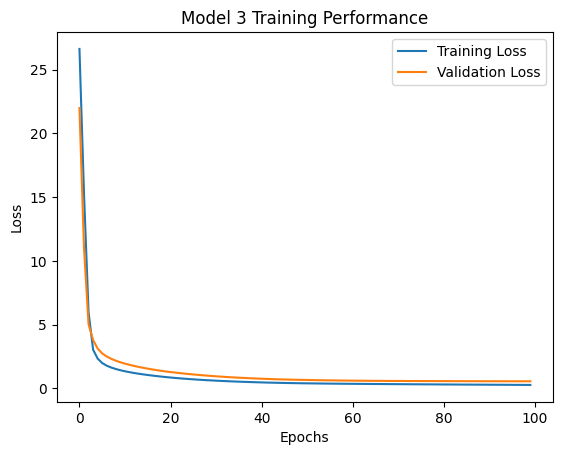

In [51]:
import matplotlib.pyplot as plt

plt.plot(history3.history['loss'], label='Training Loss')
plt.plot(history3.history['val_loss'], label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Model 3 Training Performance')
plt.legend()
plt.show()

In [52]:
print("Model 3 MAE:", result3[1])
print("Model 3 R2 Score:", score3)
print("Total Features:", X.shape[1])

Model 3 MAE: 0.5072743892669678
Model 3 R2 Score: 0.140838623046875
Total Features: 11


In [53]:
import os
print(os.getcwd())

C:\Users\salun\OneDrive\Desktop\Wine_Quality_ANN\notebooks
